# Mount Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import SelectKBest
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.feature_selection import chi2
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
from imblearn.over_sampling import SMOTENC
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, classification_report, f1_score
import joblib
import shap
from PIL import Image
import PIL

%matplotlib inline

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [ ]:
!pip install dabl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 558.5/558.5 kB 5.0 MB/s eta 0:00:00


In [ ]:
import dabl

# Read Data

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/ML/DataMining/تمرین پنجم/RTA Dataset.csv")
df.head()

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Time                         12316 non-null  object
 1   Day_of_week                  12316 non-null  object
 2   Age_band_of_driver           12316 non-null  object
 3   Sex_of_driver                12316 non-null  object
 4   Educational_level            11575 non-null  object
 5   Vehicle_driver_relation      11737 non-null  object
 6   Driving_experience           11487 non-null  object
 7   Type_of_vehicle              11366 non-null  object
 8   Owner_of_vehicle             11834 non-null  object
 9   Service_year_of_vehicle      8388 non-null   object
 10  Defect_of_vehicle            7889 non-null   object
 11  Area_accident_occured        12077 non-null  object
 12  Lanes_or_Medians             11931 non-null  object
 13  Road_allignment              12

In [ ]:
df.isnull().sum()

,0
Time,0
Day_of_week,0
Age_band_of_driver,0
Sex_of_driver,0
Educational_level,741
Vehicle_driver_relation,579
Driving_experience,829
Type_of_vehicle,950
Owner_of_vehicle,482
Service_year_of_vehicle,3928


Accident_severity
Slight Injury     10415
Serious Injury     1743
Fatal injury        158
Name: count, dtype: int64


<Axes: xlabel='Accident_severity'>

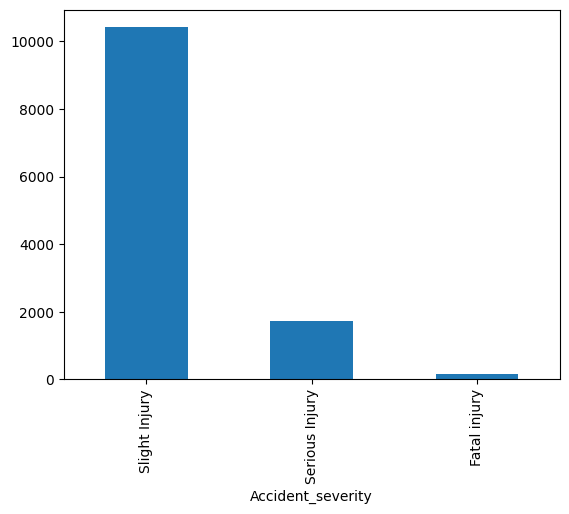

In [ ]:
print(df['Accident_severity'].value_counts())
df['Accident_severity'].value_counts().plot(kind='bar')

# Educational level

<Axes: xlabel='Educational_level'>

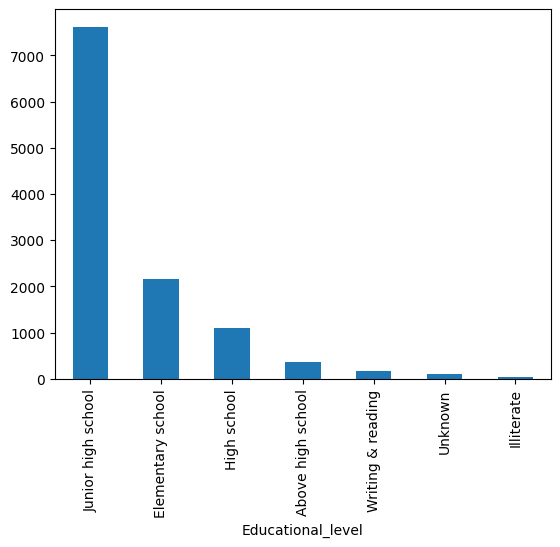

In [ ]:
df['Educational_level'].value_counts().plot(kind='bar')

<Figure size 600x500 with 0 Axes>

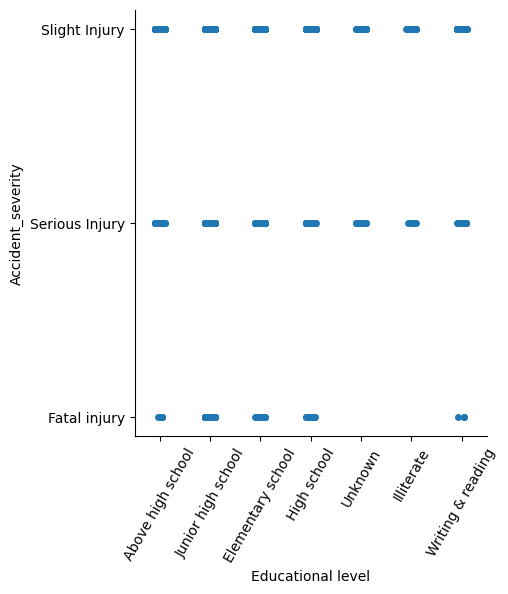

In [ ]:
# plot a point plot for categorical features and target variable
plt.figure(figsize=(6,5))
sns.catplot(x='Educational_level', y='Accident_severity', data=df)
plt.xlabel("Educational level")
plt.xticks(rotation=60)
plt.show()

# dabl data analysis

/usr/local/lib/python3.13/dist-packages/dabl/preprocessing.py:177: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(series[:10])
/usr/local/lib/python3.13/dist-packages/dabl/preprocessing.py:182: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(series)
/usr/local/lib/python3.13/dist-packages/dabl/preprocessing.py:177: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(series[:10])
/usr/local/lib/python3.13/dist-packages/dabl/preprocessing.py:177: UserWarning: Could not infer format, so each element will be parsed individually, falling back 

Target looks like classification
Showing only top 10 of 31 categorical features


/usr/local/lib/python3.13/dist-packages/dabl/plot/utils.py:622: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = data.groupby(target)[column].value_counts().unstack(target)


[<Axes: title={'center': 'Target distribution'}, xlabel='count', ylabel='Accident_severity'>,
 [array([[<Axes: xlabel='Number_of_casualties', ylabel='Number_of_casualties'>]],
        dtype=object)],
 array([[<Axes: title={'center': 'Number_of_vehicles_involved'}>,
         <Axes: title={'center': 'Types_of_Junction'}>,
         <Axes: title={'center': 'Age_band_of_driver'}>,
         <Axes: title={'center': 'Weather_conditions'}>,
         <Axes: title={'center': 'Type_of_vehicle'}>],
        [<Axes: title={'center': 'Area_accident_occured'}>,
         <Axes: title={'center': 'Cause_of_accident'}>,
         <Axes: title={'center': 'Day_of_week'}>,
         <Axes: title={'center': 'Light_conditions'}>,
         <Axes: title={'center': 'Type_of_collision'}>]], dtype=object)]

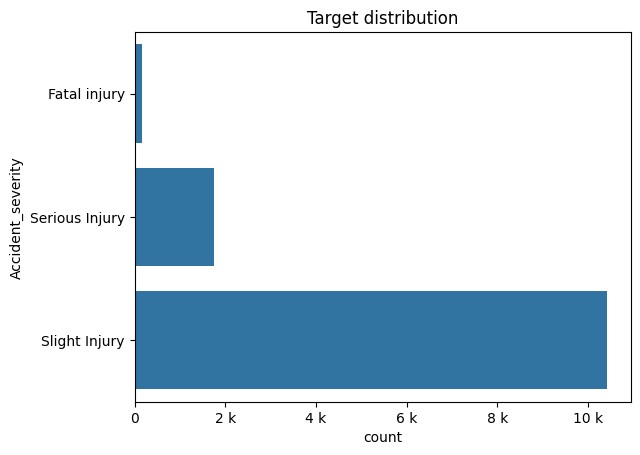

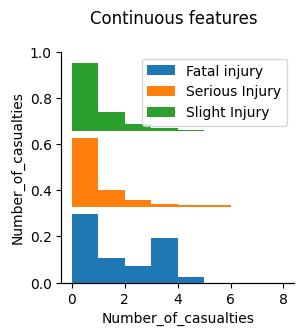

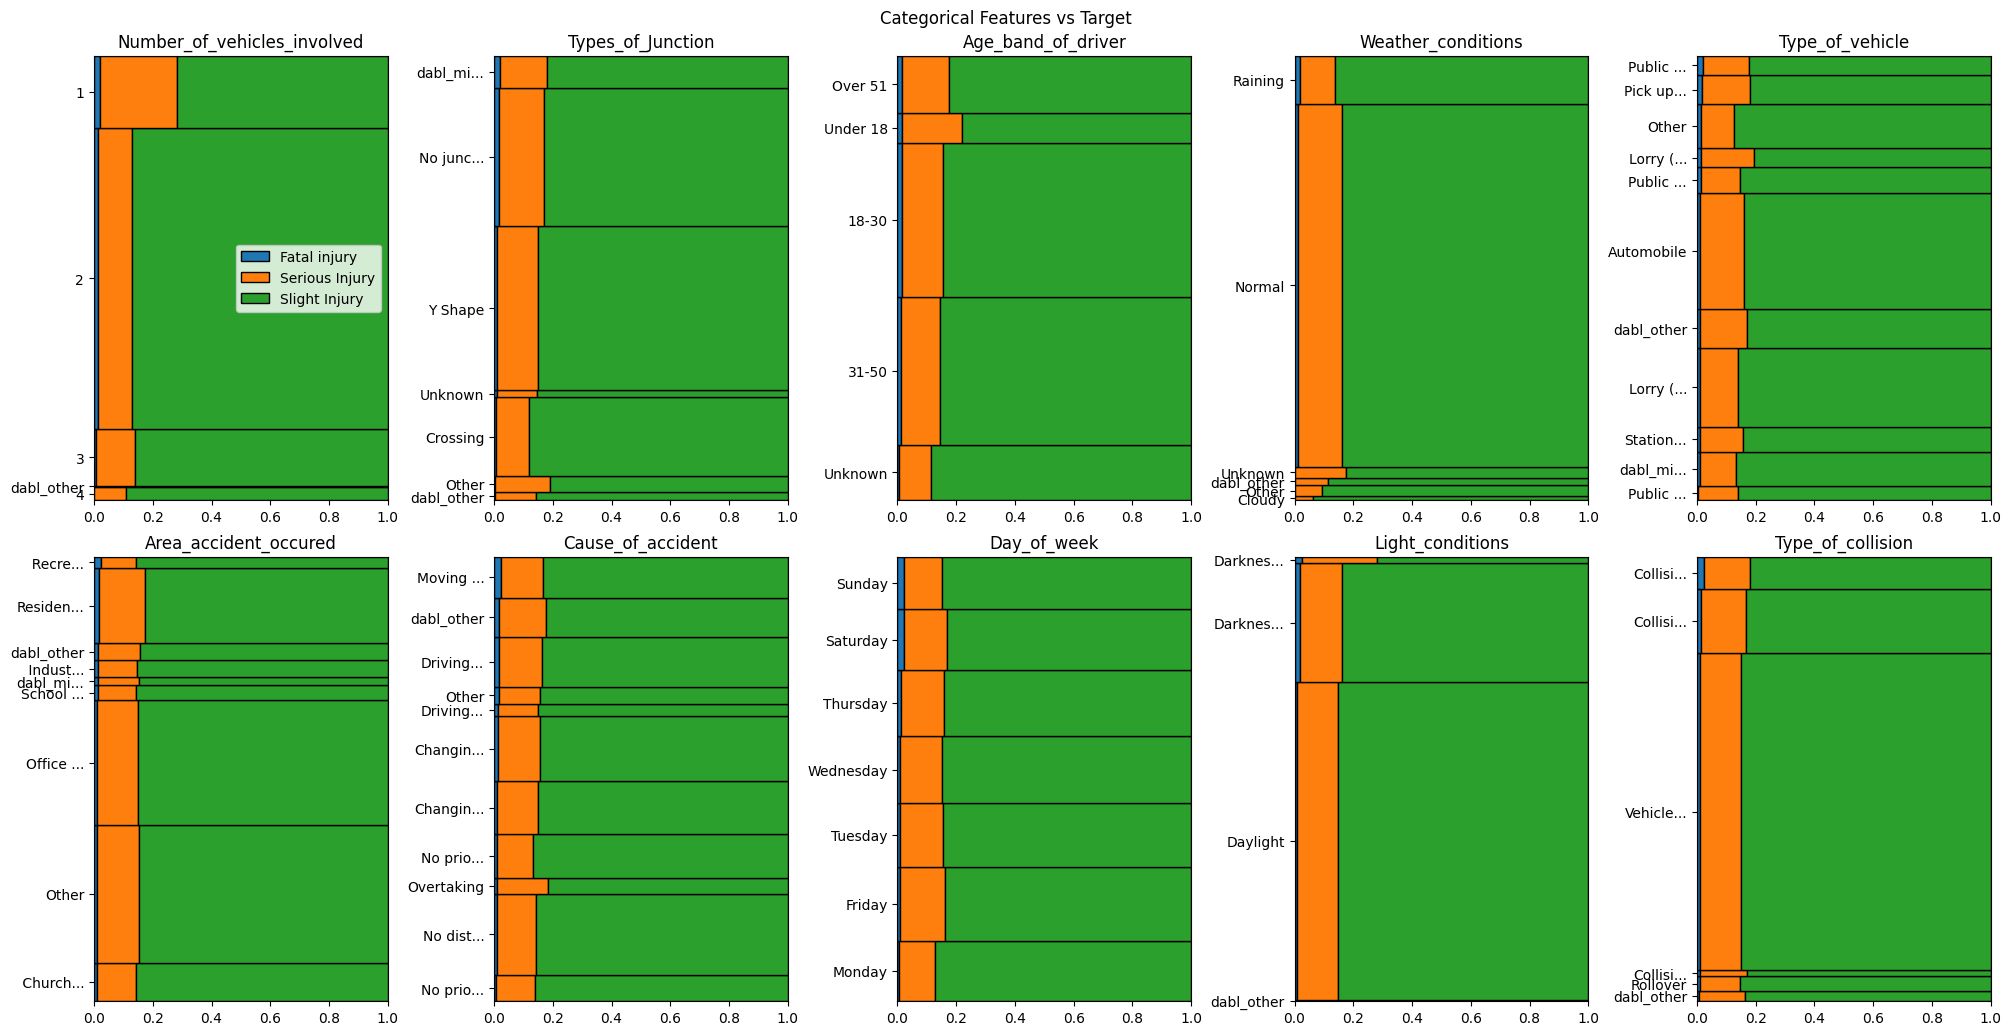

In [ ]:
dabl.plot(df, target_col='Accident_severity')

In [ ]:
#df.corr()
#df.select_dtypes(exclude = ['float', 'int']).corr()

# Some Insights from the Initial Data Analysis:

- More the Number of casualties, higher the chances of fatal injuries at accident site
- More the vehicles involved higher the chances of Serious injury
- Light_conditions being darkness can cause higher serious injury
- data is highly imbalanced
- Features like `area_accident_occured`, `Cause_of_accident`, `Day_of_week`, `type_of_junction` seem to be imporatant features causing fatal injuries
- Road_surface and road conditions do not affect fatal or serious accidents apparently

Road_surface_type
Asphalt roads                       11296
Earth roads                           358
Gravel roads                          242
Other                                 167
Asphalt roads with some distress       81
Name: count, dtype: int64


<function matplotlib.pyplot.show(close=None, block=None)>

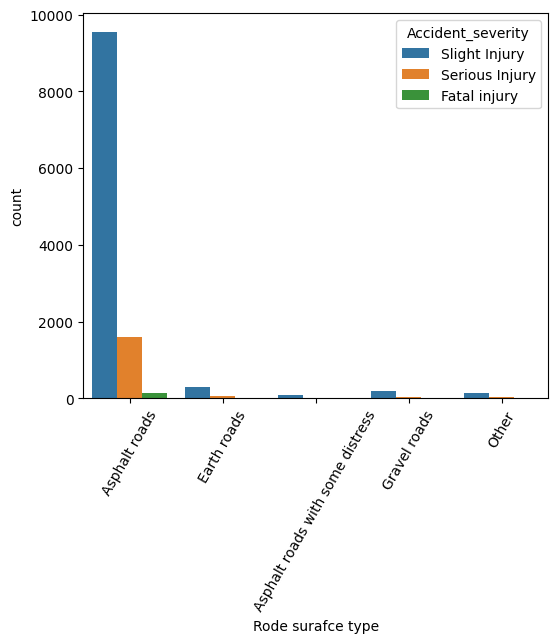

In [ ]:
print(df['Road_surface_type'].value_counts())

plt.figure(figsize=(6,5))
sns.countplot(x='Road_surface_type', hue='Accident_severity', data=df)
plt.xlabel('Rode surafce type')
plt.xticks(rotation=60)
plt.show

Road_surface_conditions
Dry                     9340
Wet or damp             2904
Snow                      70
Flood over 3cm. deep       2
Name: count, dtype: int64


<function matplotlib.pyplot.show(close=None, block=None)>

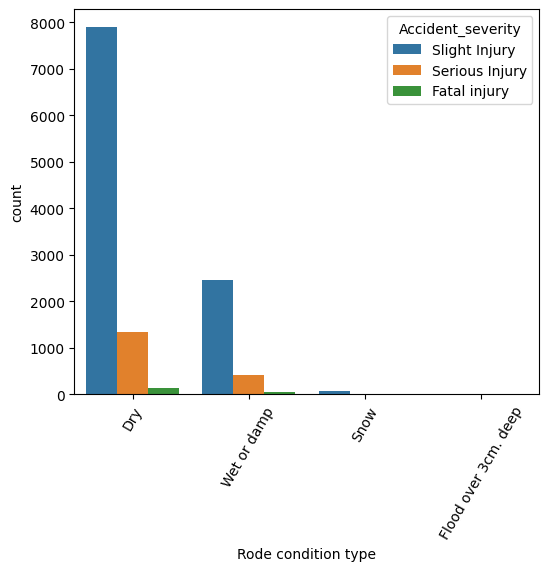

In [ ]:
print(df['Road_surface_conditions'].value_counts())

plt.figure(figsize=(6,5))
sns.countplot(x='Road_surface_conditions', hue='Accident_severity', data=df)
plt.xlabel('Rode condition type')
plt.xticks(rotation=60)
plt.show

## How does road_surface affact injuries?

In [ ]:
pivot_df = pd.pivot_table(data=df,
               index='Road_surface_conditions',
               columns='Accident_severity',
               aggfunc='count')

fatal_df = pivot_df['Road_surface_type']
fatal_df.fillna(0, inplace=True)
fatal_df['sum_of_injuries'] = fatal_df['Fatal injury'] + fatal_df['Serious Injury'] + fatal_df['Slight Injury']
fatal_df

/tmp/ipykernel_1018/3886777505.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fatal_df.fillna(0, inplace=True)
/tmp/ipykernel_1018/3886777505.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fatal_df['sum_of_injuries'] = fatal_df['Fatal injury'] + fatal_df['Serious Injury'] + fatal_df['Slight Injury']


Accident_severity,Fatal injury,Serious Injury,Slight Injury,sum_of_injuries
Road_surface_conditions,,,,
Dry,121.0,1312.0,7774.0,9207.0
Flood over 3cm. deep,0.0,0.0,2.0,2.0
Snow,0.0,4.0,65.0,69.0
Wet or damp,36.0,404.0,2426.0,2866.0


In [ ]:
fatal_df_dry = (fatal_df.loc['Dry']/fatal_df.loc['Dry','sum_of_injuries'])*100
fatal_df_dry

,Dry
Accident_severity,
Fatal injury,1.314217
Serious Injury,14.250027
Slight Injury,84.435755
sum_of_injuries,100.000000


In [ ]:
fatal_df_snow = (fatal_df.loc['Wet or damp']/fatal_df.loc['Wet or damp','sum_of_injuries'])*100
fatal_df_snow

,Wet or damp
Accident_severity,
Fatal injury,1.256106
Serious Injury,14.096301
Slight Injury,84.647592
sum_of_injuries,100.000000


In [ ]:
df.groupby('Road_surface_conditions')['Accident_severity'].count()

,Accident_severity
Road_surface_conditions,
Dry,9340
Flood over 3cm. deep,2
Snow,70
Wet or damp,2904


### Converting 'Time' feature dataype into datetime format

In [ ]:
df['Time'] = pd.to_datetime(df['Time'])

/tmp/ipykernel_1018/2145562215.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Time'] = pd.to_datetime(df['Time'])


In [ ]:
obj_cols = [col for col in df.columns if df[col].dtypes == 'object']
obj_cols2 = [col for col in obj_cols if col != 'Accident_severity']
obj_cols2

['Day_of_week',
 'Age_band_of_driver',
 'Sex_of_driver',
 'Educational_level',
 'Vehicle_driver_relation',
 'Driving_experience',
 'Type_of_vehicle',
 'Owner_of_vehicle',
 'Service_year_of_vehicle',
 'Defect_of_vehicle',
 'Area_accident_occured',
 'Lanes_or_Medians',
 'Road_allignment',
 'Types_of_Junction',
 'Road_surface_type',
 'Road_surface_conditions',
 'Light_conditions',
 'Weather_conditions',
 'Type_of_collision',
 'Vehicle_movement',
 'Casualty_class',
 'Sex_of_casualty',
 'Age_band_of_casualty',
 'Casualty_severity',
 'Work_of_casuality',
 'Fitness_of_casuality',
 'Pedestrian_movement',
 'Cause_of_accident']

### Extrating 'Hour_of_Day' feature from the time feature

In [ ]:
# remove time column from datafram
new_df = df.copy()
new_df['Hour_of_Day'] = new_df['Time'].dt.hour
n_df = new_df.drop('Time', axis=1)
n_df

,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,Defect_of_vehicle,...,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity,Hour_of_Day
0,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,No defect,...,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury,17
1,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,No defect,...,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury,17
2,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,No defect,...,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury,17
3,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,No defect,...,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury,1
4,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,No defect,...,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12311,Wednesday,31-50,Male,NaN,Employee,2-5yr,Lorry (11?40Q),Owner,NaN,No defect,...,na,na,na,na,Driver,Normal,Not a Pedestrian,No distancing,Slight Injury,16
12312,Sunday,Unknown,Male,Elementary school,Employee,5-10yr,Automobile,Owner,NaN,No defect,...,na,na,na,na,Driver,Normal,Not a Pedestrian,No distancing,Slight Injury,18
12313,Sunday,Over 51,Male,Junior high school,Employee,5-10yr,Bajaj,Owner,2-5yrs,No defect,...,Driver or rider,Male,31-50,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Serious Injury,13
12314,Sunday,18-30,Female,Junior high school,Employee,Above 10yr,Lorry (41?100Q),Owner,2-5yrs,No defect,...,na,na,na,na,Driver,Normal,Not a Pedestrian,Driving under the influence of drugs,Slight Injury,13


## categorical data visualization

/tmp/ipykernel_1018/3679874097.py:7: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(5,5))


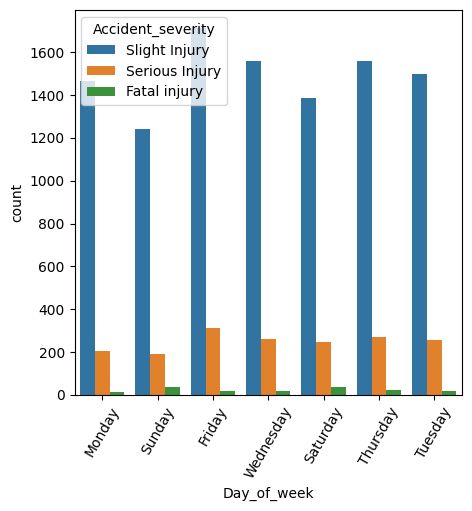

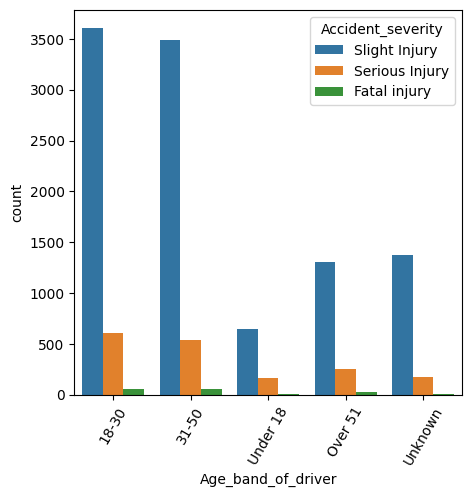

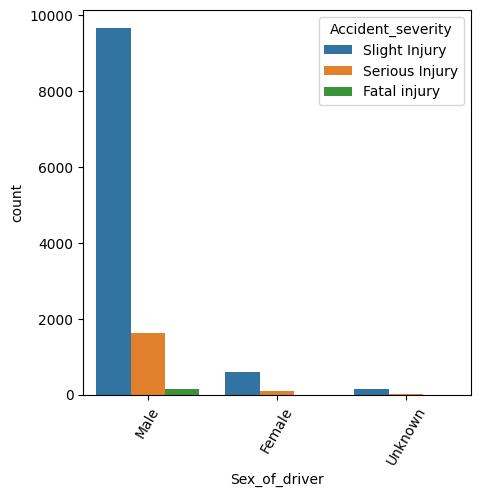

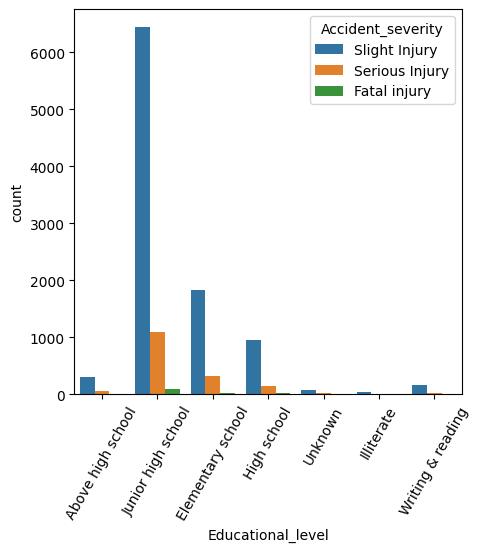

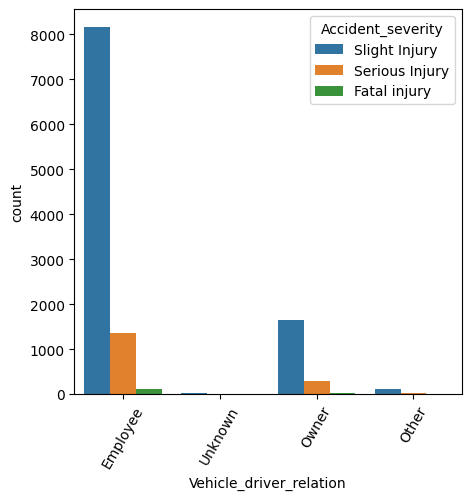

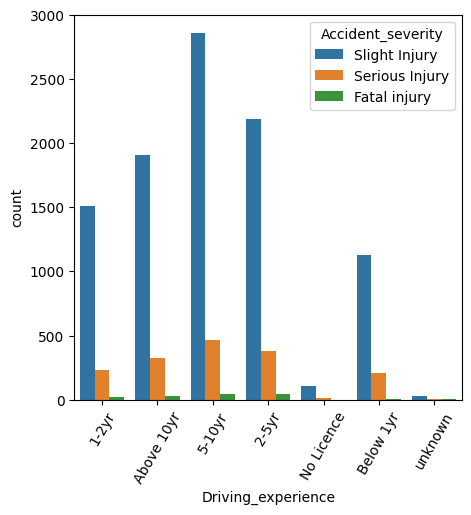

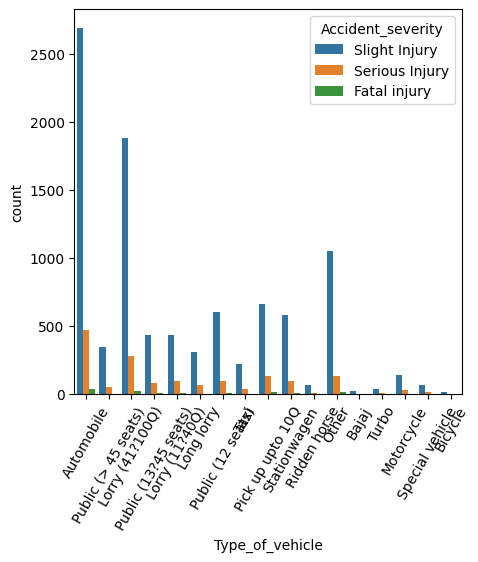

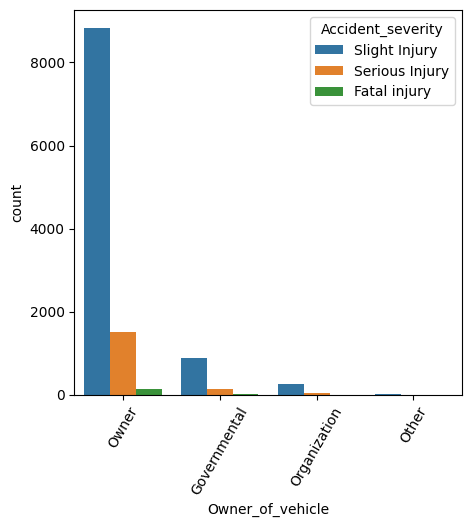

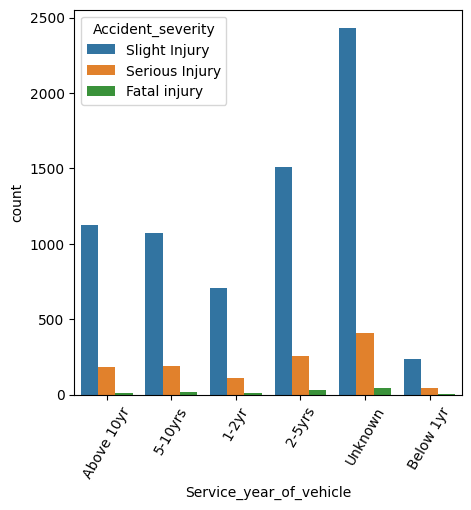

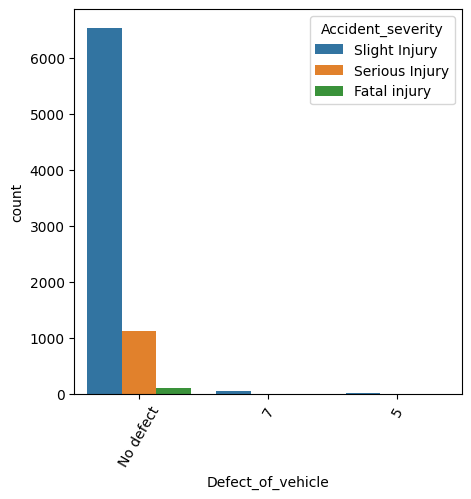

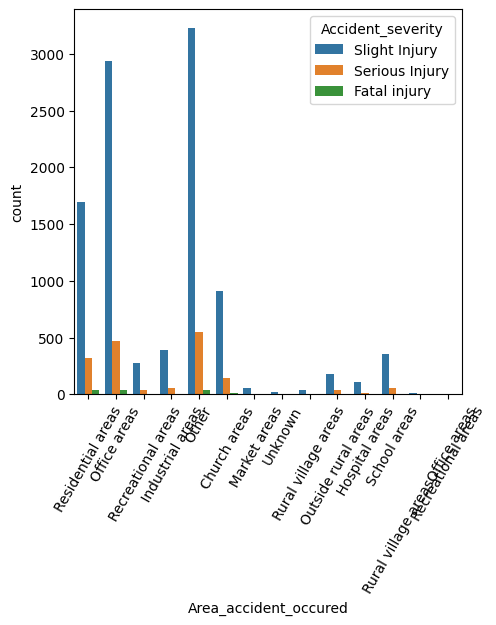

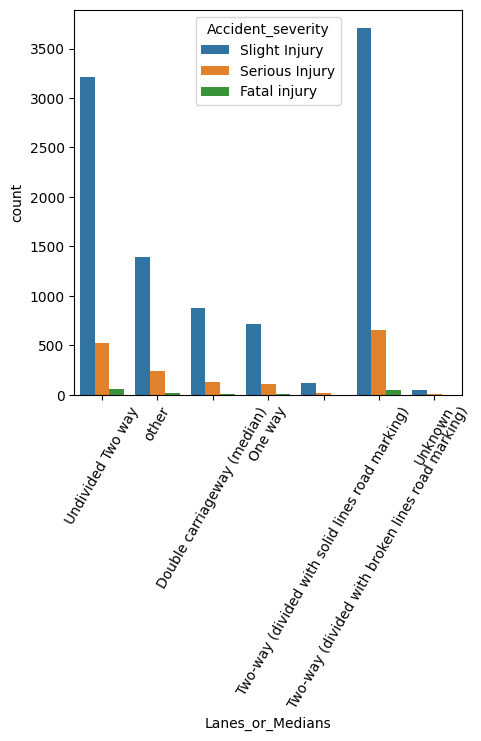

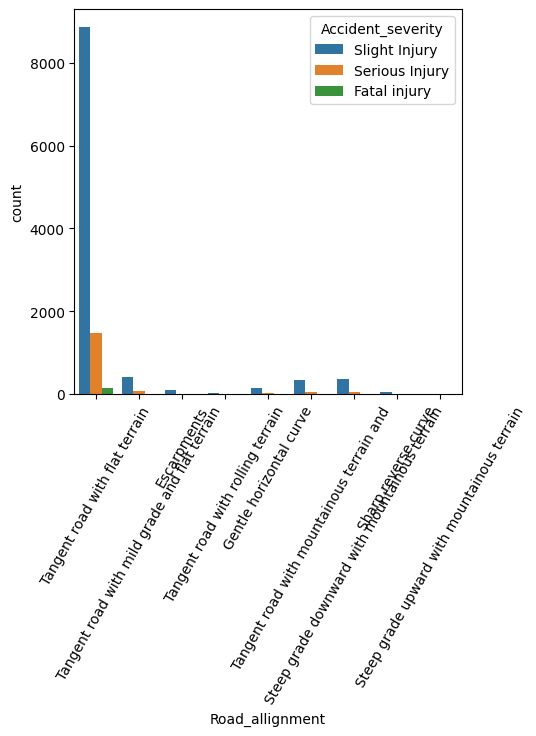

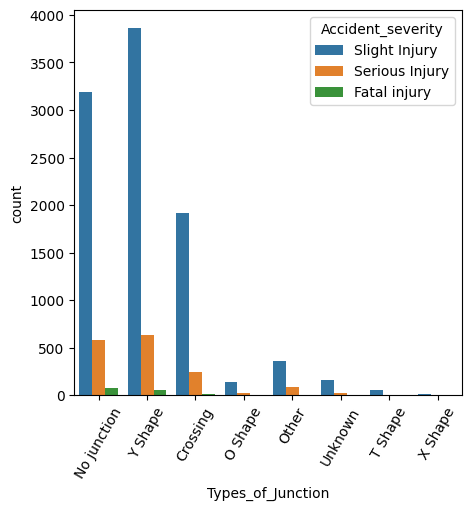

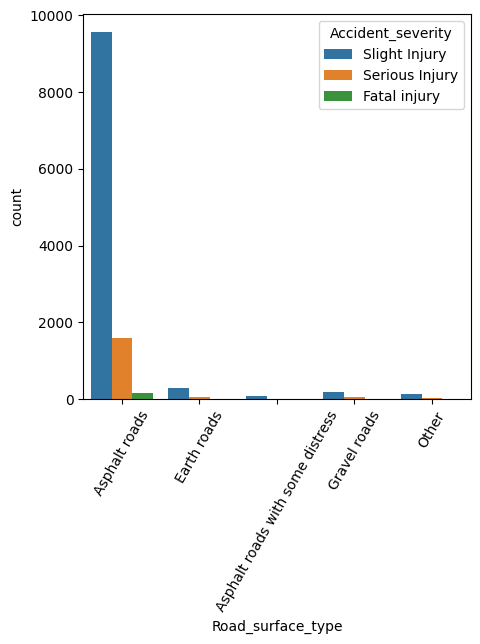

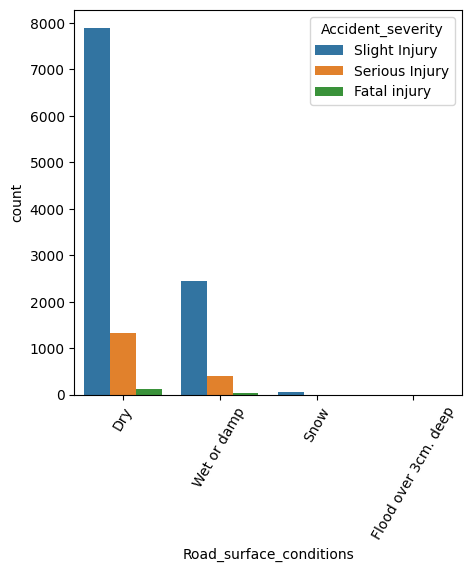

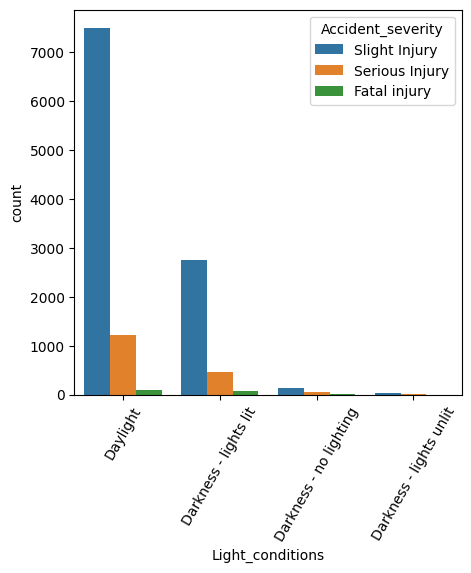

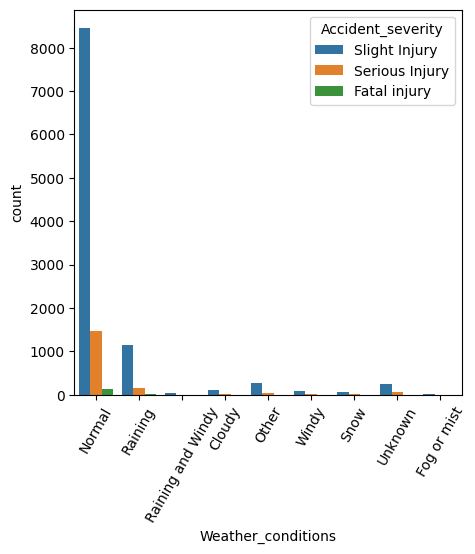

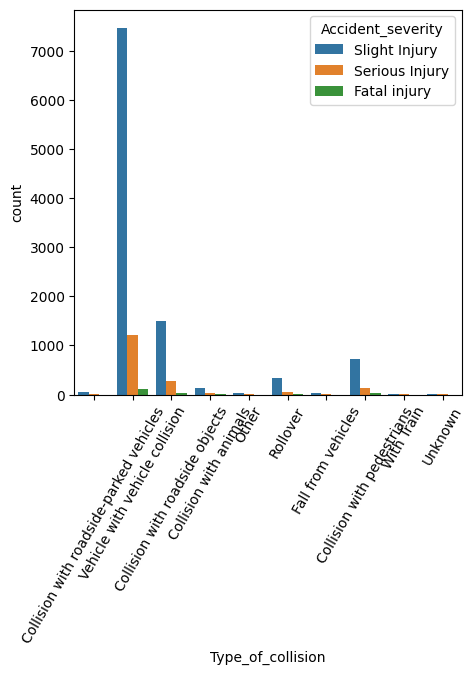

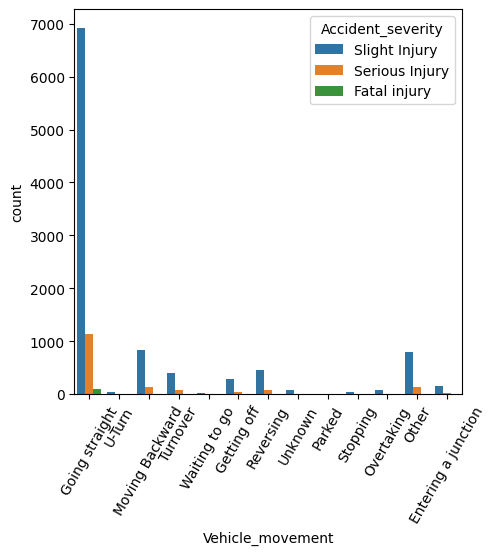

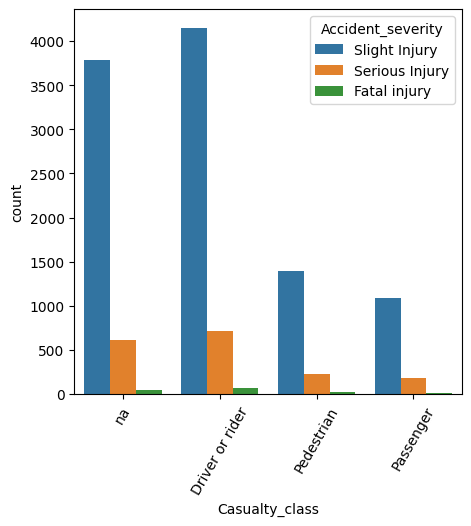

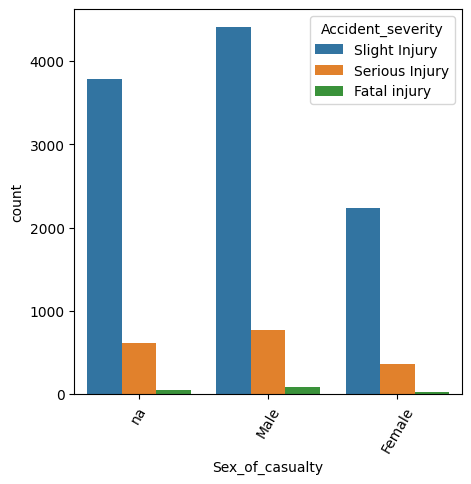

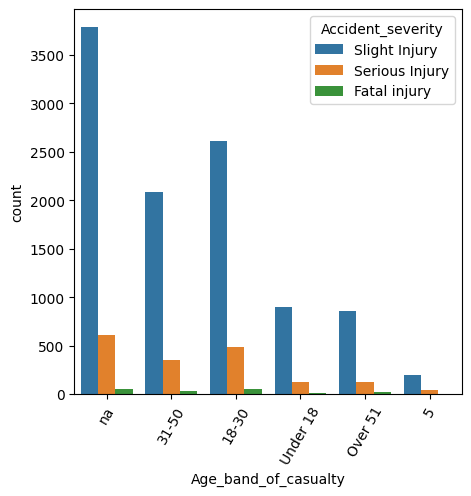

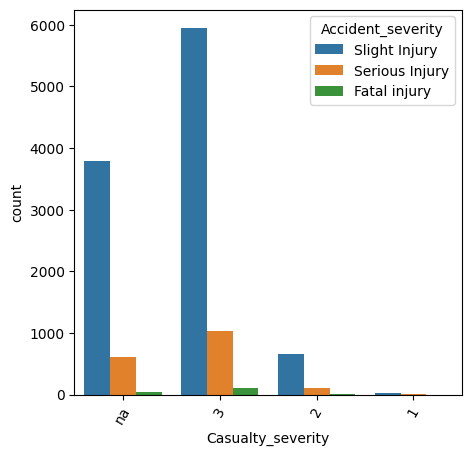

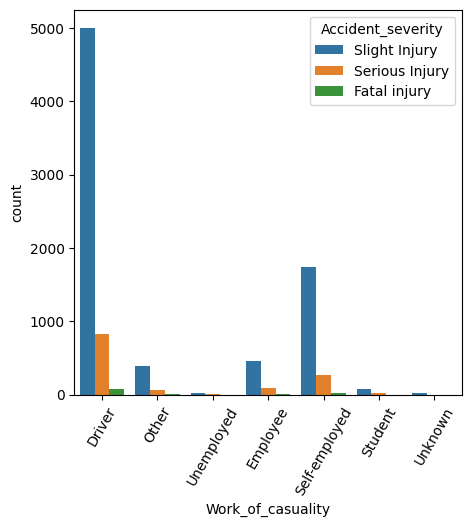

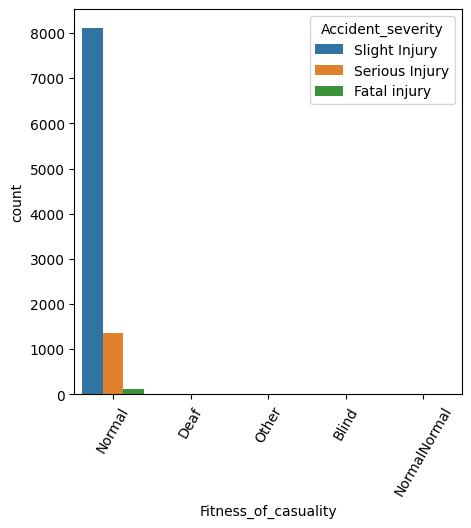

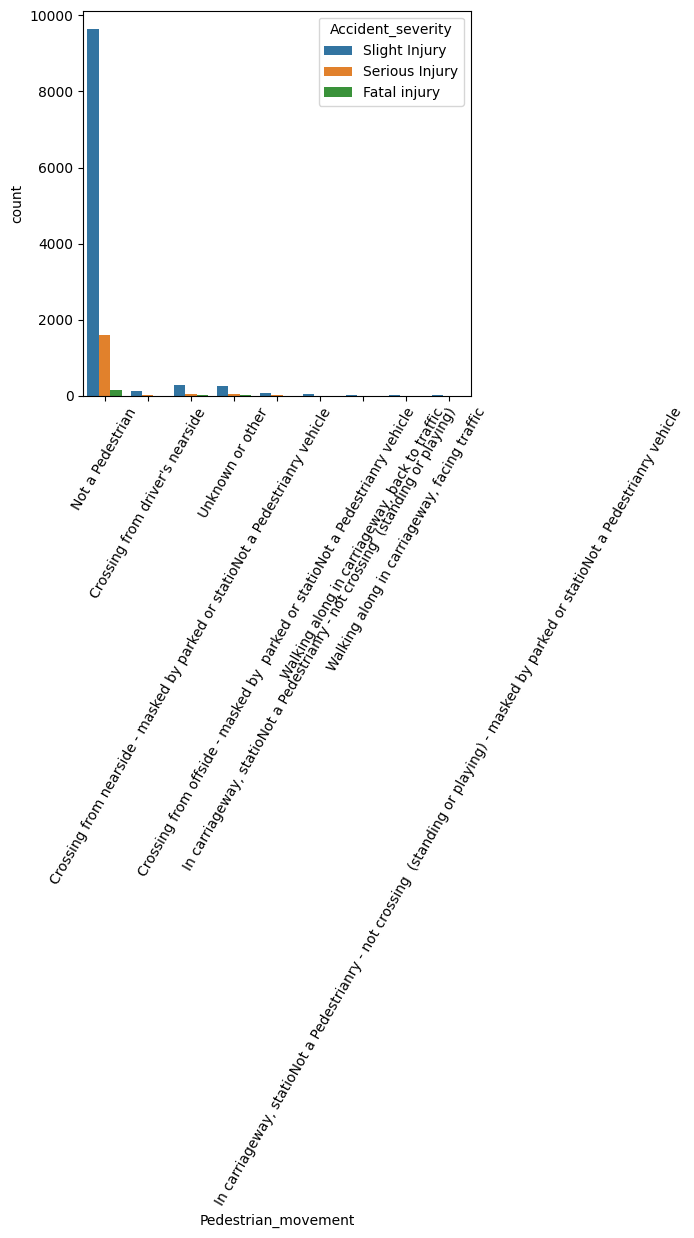

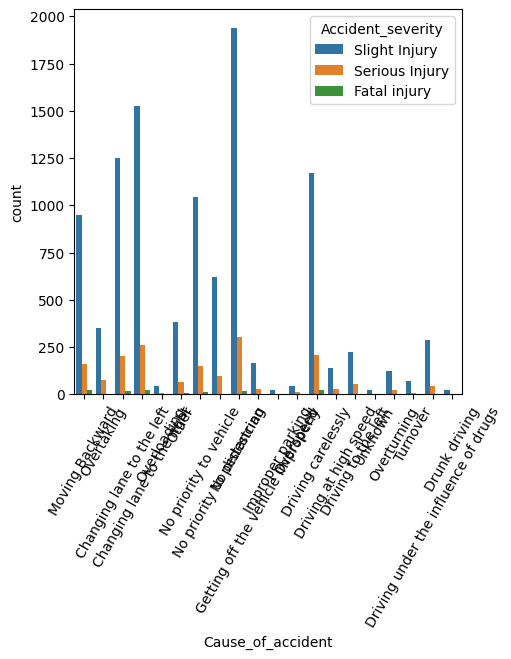

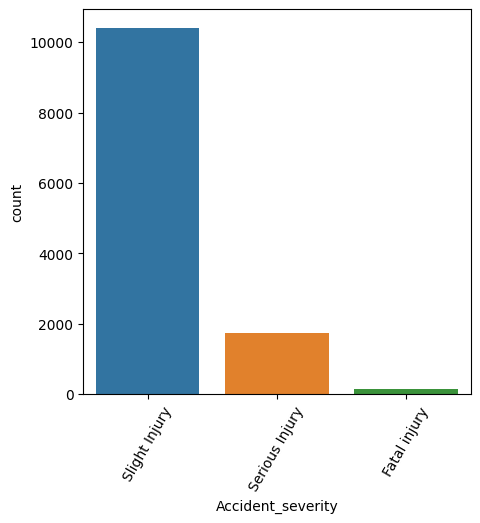

In [ ]:
# data visualizationf of categorical cols

def count_plot(col):
    n_df[col].value_counts()

    # plot the figure of count plot
    plt.figure(figsize=(5,5))
    sns.countplot(x=col, hue='Accident_severity', data=n_df)
    plt.xlabel(f'{col}')
    plt.xticks(rotation=60)
    plt.show

for col in obj_cols:
    count_plot(col)

<Figure size 500x500 with 0 Axes>

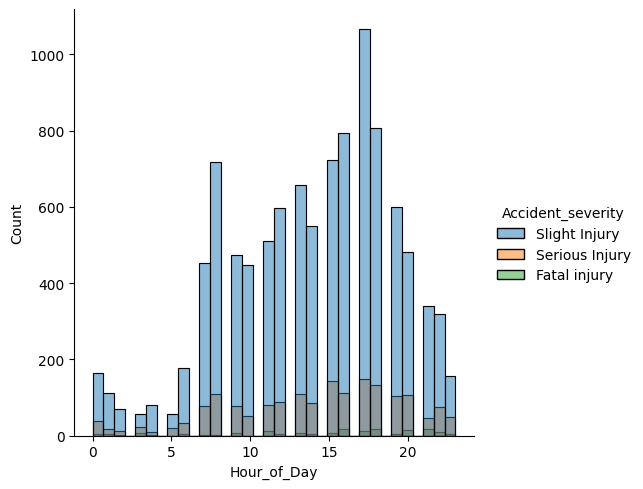

In [ ]:
# disribution of hour of the day
plt.figure(figsize=(5,5))
sns.displot(x='Hour_of_Day', hue='Accident_severity', data=n_df)
plt.show()

# Final Insights and Steps Further

- `Hour_of_Day` seems important to predict target
- Lots of redundant features needs to be removed
- Initially, Total 18 features are selected based on EDA and basic understanding of domain knowledge
- Handle the missing values in these 20 features
- Feature selection using scikit-libraries
- Encoding categorical features
- Handle imbalance dataset
- features standardization
- modelling
- Evalution and Hyper-parameter tuning
- selecting 17 features based on EDA insights and their informativeness to target feature

# Data pre-processing

In [ ]:
# feature selection based on visualization (to_be_continue)
features = ['Day_of_week','Number_of_vehicles_involved','Number_of_casualties','Area_accident_occured',
           'Types_of_Junction','Age_band_of_driver','Sex_of_driver','Educational_level',
           'Vehicle_driver_relation','Type_of_vehicle','Driving_experience','Service_year_of_vehicle','Type_of_collision',
           'Sex_of_casualty','Age_band_of_casualty','Cause_of_accident','Hour_of_Day']
len(features)

17

In [ ]:
# new dataframe generated
featureset_df = n_df[features]
target = n_df['Accident_severity']

In [ ]:
# meta data of the new sub dataset
featureset_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Day_of_week                  12316 non-null  object
 1   Number_of_vehicles_involved  12316 non-null  int64 
 2   Number_of_casualties         12316 non-null  int64 
 3   Area_accident_occured        12077 non-null  object
 4   Types_of_Junction            11429 non-null  object
 5   Age_band_of_driver           12316 non-null  object
 6   Sex_of_driver                12316 non-null  object
 7   Educational_level            11575 non-null  object
 8   Vehicle_driver_relation      11737 non-null  object
 9   Type_of_vehicle              11366 non-null  object
 10  Driving_experience           11487 non-null  object
 11  Service_year_of_vehicle      8388 non-null   object
 12  Type_of_collision            12161 non-null  object
 13  Sex_of_casualty              12

## Missing value treatment

In [ ]:
feature_df = featureset_df.copy()

**Missing value approch**

- Most the missing values in features could be result of non-availability during investigation of the accident site, hence we will replace it as a 'Unknown' in all the columns in this case.  

In [ ]:
# NaN are missing because service info might not be available, we will fill as 'Unknowns'
feature_df['Service_year_of_vehicle'] = feature_df['Service_year_of_vehicle'].fillna('Unknown')
feature_df['Types_of_Junction'] = feature_df['Types_of_Junction'].fillna('Unknown')
feature_df['Area_accident_occured'] = feature_df['Area_accident_occured'].fillna('Unknown')
feature_df['Driving_experience'] = feature_df['Driving_experience'].fillna('unknown')
feature_df['Type_of_vehicle'] = feature_df['Type_of_vehicle'].fillna('Other')
feature_df['Vehicle_driver_relation'] = feature_df['Vehicle_driver_relation'].fillna('Unknown')
feature_df['Educational_level'] = feature_df['Educational_level'].fillna('Unknown')
feature_df['Type_of_collision'] = feature_df['Type_of_collision'].fillna('Unknown')

In [ ]:
feature_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Day_of_week                  12316 non-null  object
 1   Number_of_vehicles_involved  12316 non-null  int64 
 2   Number_of_casualties         12316 non-null  int64 
 3   Area_accident_occured        12316 non-null  object
 4   Types_of_Junction            12316 non-null  object
 5   Age_band_of_driver           12316 non-null  object
 6   Sex_of_driver                12316 non-null  object
 7   Educational_level            12316 non-null  object
 8   Vehicle_driver_relation      12316 non-null  object
 9   Type_of_vehicle              12316 non-null  object
 10  Driving_experience           12316 non-null  object
 11  Service_year_of_vehicle      12316 non-null  object
 12  Type_of_collision            12316 non-null  object
 13  Sex_of_casualty              12

## Train Test Split

In [ ]:

from sklearn.model_selection import train_test_split

X = feature_df.copy()
y = target.copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
print("Train:")
print(y_train.value_counts())

print("\nTest:")
print(y_test.value_counts())

Train:
Accident_severity
Slight Injury     8331
Serious Injury    1394
Fatal injury       127
Name: count, dtype: int64

Test:
Accident_severity
Slight Injury     2084
Serious Injury     349
Fatal injury        31
Name: count, dtype: int64


## One Hot Encoding

- One-hot encoding to encode categorical features and LabelEncoder() to encode the labels

In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore')

X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

print("Train shape:", X_train_encoded.shape)
print("Test shape:", X_test_encoded.shape)

Train shape: (9852, 154)
Test shape: (2464, 154)


## Lable encoding of Target Feature

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)
print("Train shape:", y_train_encoded.shape)
print("Test shape:", y_test_encoded.shape)

Classes: ['Fatal injury' 'Serious Injury' 'Slight Injury']
Train shape: (9852,)
Test shape: (2464,)


## Feature selection using k best chi2 method

In [ ]:
selector = SelectKBest(score_func=chi2, k=50)

X_train_selected = selector.fit_transform(X_train_encoded, y_train_encoded)
X_test_selected = selector.transform(X_test_encoded)

print("Train shape:", X_train_selected.shape)
print("Test shape:", X_test_selected.shape)

Train shape: (9852, 50)
Test shape: (2464, 50)


## Imbalance data treatment

In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_selected,
    y_train_encoded
)

print("Before SMOTE:", X_train_selected.shape)
print("After SMOTE:", X_train_resampled.shape)
print("\nClass counts after SMOTE:")
print(pd.Series(y_train_resampled).value_counts())

Before SMOTE: (9852, 50)
After SMOTE: (24993, 50)

Class counts after SMOTE:
2    8331
1    8331
0    8331
Name: count, dtype: int64


# Modeling

## Decision tree

In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

dt_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)


dt_model.fit(X_train_resampled, y_train_resampled)


y_pred_dt = dt_model.predict(X_test_selected)

print(classification_report(
    y_test_encoded,
    y_pred_dt,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test_encoded,
    y_pred_dt,
    labels=range(len(label_encoder.classes_))
))


                precision    recall  f1-score   support

  Fatal injury       0.15      0.16      0.16        31
Serious Injury       0.21      0.24      0.23       349
 Slight Injury       0.86      0.84      0.85      2084

      accuracy                           0.75      2464
     macro avg       0.41      0.41      0.41      2464
  weighted avg       0.76      0.75      0.75      2464

Confusion Matrix:
[[   5    1   25]
 [   4   85  260]
 [  24  312 1748]]


In [ ]:

from sklearn.metrics import accuracy_score, f1_score


y_train_pred = dt_model.predict(X_train_selected)
y_test_pred = dt_model.predict(X_test_selected)


print("Train Accuracy:", accuracy_score(y_train_encoded, y_train_pred))
print("Test Accuracy:", accuracy_score(y_test_encoded, y_test_pred))

print("Train Macro F1:", f1_score(y_train_encoded, y_train_pred, average='macro'))
print("Test Macro F1:", f1_score(y_test_encoded, y_test_pred, average='macro'))


Train Accuracy: 0.9772634997969956
Test Accuracy: 0.7459415584415584
Train Macro F1: 0.9584595267932846
Test Macro F1: 0.41099632857937024


### Grid search of Decision tree

In [ ]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {
    'max_depth': [5, 10, 15, None],
    'min_samples_leaf': [5, 10, 20],
    'min_samples_split': [2, 10, 20],
    'criterion': ['gini', 'entropy'],
    'class_weight': [None, 'balanced']
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_smote = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search_smote.fit(
    X_train_resampled,
    y_train_resampled
)

print("Best Parameters:", grid_search_smote.best_params_)
print("Best CV Macro F1:", grid_search_smote.best_score_)


Fitting 5 folds for each of 144 candidates, totalling 720 fits
Best Parameters: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best CV Macro F1: 0.8766212843917403


In [ ]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

best_tree_smote = grid_search_smote.best_estimator_

y_pred_smote = best_tree_smote.predict(X_test_selected)

print("Classification Report:")
print(classification_report(
    y_test_encoded,
    y_pred_smote,
    target_names=label_encoder.classes_,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_encoded, y_pred_smote))

print("Accuracy:", accuracy_score(y_test_encoded, y_pred_smote))
print("Macro F1:", f1_score(
    y_test_encoded,
    y_pred_smote,
    average='macro'
))


Classification Report:
                precision    recall  f1-score   support

  Fatal injury       0.05      0.03      0.04        31
Serious Injury       0.24      0.21      0.23       349
 Slight Injury       0.86      0.88      0.87      2084

      accuracy                           0.78      2464
     macro avg       0.38      0.38      0.38      2464
  weighted avg       0.76      0.78      0.77      2464

Confusion Matrix:
[[   1    3   27]
 [   3   74  272]
 [  16  227 1841]]
Accuracy: 0.7775974025974026
Macro F1: 0.37918251347362464


## Sensitivity Analize

In [ ]:

import pandas as pd

results = pd.DataFrame(grid_search_smote.cv_results_)

params = [
    'max_depth',
    'min_samples_leaf',
    'min_samples_split',
    'criterion',
    'class_weight'
]

for param in params:
    print(f"\n{'='*45}")
    print(f"Sensitivity Analysis: {param}")
    print('='*45)

    summary = (
        results.groupby(f'param_{param}', dropna=False, observed=True)
        ['mean_test_score']
        .mean()
        .sort_values(ascending=False)
    )

    for value, score in summary.items():
        print(f"{value}: Macro F1 = {score:.4f}")



Sensitivity Analysis: max_depth
nan: Macro F1 = 0.8458
15.0: Macro F1 = 0.8028
10.0: Macro F1 = 0.7298
5.0: Macro F1 = 0.5498

Sensitivity Analysis: min_samples_leaf
5: Macro F1 = 0.7435
10: Macro F1 = 0.7340
20: Macro F1 = 0.7187

Sensitivity Analysis: min_samples_split
2: Macro F1 = 0.7324
10: Macro F1 = 0.7324
20: Macro F1 = 0.7314

Sensitivity Analysis: criterion
entropy: Macro F1 = 0.7340
gini: Macro F1 = 0.7301

Sensitivity Analysis: class_weight
balanced: Macro F1 = 0.7321
nan: Macro F1 = 0.7320


## Navie Bayes

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix

nb_model = MultinomialNB()

nb_model.fit(X_train_resampled, y_train_resampled)

y_pred_nb = nb_model.predict(X_test_selected)

print(classification_report(
    y_test_encoded,
    y_pred_nb,
    target_names=label_encoder.classes_,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_encoded, y_pred_nb))

                precision    recall  f1-score   support

  Fatal injury       0.02      0.39      0.05        31
Serious Injury       0.19      0.40      0.26       349
 Slight Injury       0.88      0.53      0.66      2084

      accuracy                           0.51      2464
     macro avg       0.36      0.44      0.32      2464
  weighted avg       0.77      0.51      0.60      2464

Confusion Matrix:
[[  12   10    9]
 [  68  138  143]
 [ 408  573 1103]]


### Grid search of Navie Bayes

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()

param_grid_nb = {
    'alpha': [0.01, 0.1, 0.5, 1, 2, 5, 10],
    'fit_prior': [True, False]
}

grid_nb = GridSearchCV(
    estimator=nb,
    param_grid=param_grid_nb,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1
)

grid_nb.fit(X_train_resampled, y_train_resampled)

print("Best parameters:", grid_nb.best_params_)
print("Best CV Macro F1:", grid_nb.best_score_)

Best parameters: {'alpha': 0.01, 'fit_prior': False}
Best CV Macro F1: 0.5567833383722355


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

best_nb = grid_nb.best_estimator_

y_pred_best_nb = best_nb.predict(X_test_selected)

print(classification_report(
    y_test_encoded,
    y_pred_best_nb,
    target_names=label_encoder.classes_,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_encoded, y_pred_best_nb))

                precision    recall  f1-score   support

  Fatal injury       0.02      0.39      0.05        31
Serious Injury       0.19      0.40      0.26       349
 Slight Injury       0.88      0.53      0.66      2084

      accuracy                           0.51      2464
     macro avg       0.37      0.44      0.32      2464
  weighted avg       0.77      0.51      0.60      2464

Confusion Matrix:
[[  12   10    9]
 [  68  138  143]
 [ 407  573 1104]]


## Sensitivity Analize

In [ ]:

import pandas as pd

results_nb = pd.DataFrame(grid_nb.cv_results_)

params_nb = ['alpha', 'fit_prior']

for param in params_nb:
    print(f"\n{'='*40}")
    print(f"Sensitivity Analysis: {param}")
    print('='*40)

    summary = (
        results_nb
        .groupby(f'param_{param}', dropna=False)['mean_test_score']
        .mean()
        .sort_values(ascending=False)
    )

    for value, score in summary.items():
        print(f"{value}: Macro F1 = {score:.4f}")



Sensitivity Analysis: alpha
0.01: Macro F1 = 0.5568
0.1: Macro F1 = 0.5567
0.5: Macro F1 = 0.5567
1.0: Macro F1 = 0.5565
2.0: Macro F1 = 0.5562
5.0: Macro F1 = 0.5559
10.0: Macro F1 = 0.5555

Sensitivity Analysis: fit_prior
False: Macro F1 = 0.5563
True: Macro F1 = 0.5563


## Mlp

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

#scaler = StandardScaler()
scaler = StandardScaler(with_mean=False)

X_train_scaled = scaler.fit_transform(X_train_resampled)
X_test_scaled = scaler.transform(X_test_selected)

nn_model = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=300,
    random_state=42
)

nn_model.fit(X_train_scaled, y_train_resampled)

y_pred_nn = nn_model.predict(X_test_scaled)

print(classification_report(
    y_test_encoded,
    y_pred_nn,
    target_names=label_encoder.classes_,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_encoded, y_pred_nn))

                precision    recall  f1-score   support

  Fatal injury       0.03      0.03      0.03        31
Serious Injury       0.22      0.18      0.20       349
 Slight Injury       0.86      0.88      0.87      2084

      accuracy                           0.77      2464
     macro avg       0.37      0.36      0.36      2464
  weighted avg       0.76      0.77      0.76      2464

Confusion Matrix:
[[   1    5   25]
 [   4   64  281]
 [  31  227 1826]]


### Grid search of MLP

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier

nn_model = MLPClassifier(
    max_iter=150,
    random_state=42,
    early_stopping=True
)

param_grid_nn = {
    'hidden_layer_sizes': [(50,), (100,)],
    'alpha': [0.001, 0.01]
}

grid_nn = GridSearchCV(
    estimator=nn_model,
    param_grid=param_grid_nn,
    scoring='f1_macro',
    cv=3,
    n_jobs=-1
)

grid_nn.fit(X_train_scaled, y_train_resampled)


print("Best Parameters:", grid_nn.best_params_)
print("Best CV Macro F1:", grid_nn.best_score_)


Best Parameters: {'alpha': 0.001, 'hidden_layer_sizes': (100,)}
Best CV Macro F1: 0.8997414761719112


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

best_nn = grid_nn.best_estimator_
y_pred_nn_best = best_nn.predict(X_test_scaled)

print(classification_report(
    y_test_encoded,
    y_pred_nn_best,
    target_names=label_encoder.classes_,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_encoded, y_pred_nn_best))
print("Accuracy:", accuracy_score(y_test_encoded, y_pred_nn_best))
print("Macro F1:", f1_score(y_test_encoded, y_pred_nn_best, average='macro'))

                precision    recall  f1-score   support

  Fatal injury       0.06      0.06      0.06        31
Serious Injury       0.19      0.22      0.21       349
 Slight Injury       0.86      0.84      0.85      2084

      accuracy                           0.74      2464
     macro avg       0.37      0.37      0.37      2464
  weighted avg       0.75      0.74      0.75      2464

Confusion Matrix:
[[   2    8   21]
 [   5   77  267]
 [  26  312 1746]]
Accuracy: 0.7406655844155844
Macro F1: 0.37230625827629177


## Sensitivity Analize

In [ ]:

import pandas as pd

results_nn = pd.DataFrame(grid_nn.cv_results_)

params_nn = ['hidden_layer_sizes', 'alpha']

for param in params_nn:
    print(f"\n{'='*45}")
    print(f"Sensitivity Analysis: {param}")
    print('='*45)

    summary = (
        results_nn
        .groupby(f'param_{param}', dropna=False)['mean_test_score']
        .mean()
        .sort_values(ascending=False)
    )

    for value, score in summary.items():
        print(f"{value}: Macro F1 = {score:.4f}")



Sensitivity Analysis: hidden_layer_sizes
(100,): Macro F1 = 0.8994
(50,): Macro F1 = 0.8605

Sensitivity Analysis: alpha
0.001: Macro F1 = 0.8803
0.01: Macro F1 = 0.8797
